In [1]:
from pathlib import Path
import json

PROJECT_ROOT = Path.cwd().parent

CHUNKS_DIR = PROJECT_ROOT / "data" / "chunks"

chunk_files = list(CHUNKS_DIR.glob("*_chunks.json"))

print("Chunk files:", len(chunk_files))

for f in chunk_files:
    print(f.name)

Chunk files: 11
doc_127ff1e6f5f2_chunks.json
doc_1a26eba6c592_chunks.json
doc_538d7233661b_chunks.json
doc_6a8ad8a50fb1_chunks.json
doc_83ca7df91b16_chunks.json
doc_9499a9575556_chunks.json
doc_ac6daafe7996_chunks.json
doc_b3b3e5754724_chunks.json
doc_c46fe4f241a4_chunks.json
doc_d34c8b40ce9b_chunks.json
doc_e37d68152c78_chunks.json


In [3]:
# Step 2 — Inspect one real chunk

import json

sample_file = chunk_files[0]

with open(sample_file, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

print("File:", sample_file.name)
print("Top-level type:", type(sample_data).__name__)
print("Top-level keys:", sample_data.keys())

# Find the actual chunk list
chunks = sample_data["chunks"]

print("Number of chunks:", len(chunks))

print("\nFirst chunk:")
print(json.dumps(chunks[0], indent=2, ensure_ascii=False))

File: doc_127ff1e6f5f2_chunks.json
Top-level type: dict
Top-level keys: dict_keys(['document_id', 'chunks', 'validation'])
Number of chunks: 211

First chunk:
{
  "chunk_id": "chunk_634b3e042dffad81",
  "document_id": "doc_127ff1e6f5f2",
  "source_file": "ssrn-5231379.pdf",
  "chunk_index": 0,
  "chunk_type": "semantic",
  "text": "NIHAD ALIYEV AND XINYI DENG University of Technology Sydney Abstract. We study the impact of quantitative trading strategies (quants) on price efficiency by developing a model that incorporates two defining features of quants: superior information processing capacity and limited strategic awareness. These forces have opposing effects on trading aggressiveness-better information pro- cessing increases it, while limited strategic awareness decreases it. As a result, an increase in quant participation deteriorates price efficiency when their information quality is low, improves it when information quality is high, and produces a non-monotonic effect in between.

In [4]:
# Step 3 — Create evaluation candidate inventory

import json
from collections import Counter

all_chunks = []

for file in chunk_files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    all_chunks.extend(data["chunks"])

print("Total chunks:", len(all_chunks))

print("\nChunk types:")
print(Counter(c["chunk_type"] for c in all_chunks))

print("\nContent types:")
print(Counter(
    ct
    for c in all_chunks
    for ct in c.get("content_types", [])
))

print("\nChunks containing formulas:",
      sum(bool(c.get("formula_ids")) for c in all_chunks))

print("Chunks containing tables:",
      sum(bool(c.get("table_ids")) for c in all_chunks))

print("Chunks containing figures:",
      sum(bool(c.get("figure_ids")) for c in all_chunks))

print("\nDocuments:")
doc_counts = Counter(c["source_file"] for c in all_chunks)

for doc, count in doc_counts.items():
    print(f"{doc}: {count} chunks")

Total chunks: 1141

Chunk types:
Counter({'semantic': 695, 'formula_evidence': 301, 'figure_evidence': 77, 'table_evidence': 68})

Content types:
Counter({'text': 695, 'formula': 301, 'figure': 77, 'table': 68})

Chunks containing formulas: 301
Chunks containing tables: 68
Chunks containing figures: 77

Documents:
ssrn-5231379.pdf: 211 chunks
2605.28853v1.pdf: 79 chunks
2605.21504v1.pdf: 36 chunks
2605.27848v1.pdf: 69 chunks
2605.27945v1.pdf: 153 chunks
2605.23959v1.pdf: 112 chunks
2605.25894v1.pdf: 34 chunks
2605.29413v1.pdf: 100 chunks
2605.27977v1.pdf: 92 chunks
2605.23953v1.pdf: 64 chunks
2508.15237v2 (1).pdf: 191 chunks


In [5]:
# Step 4 — Build candidate pools for evaluation benchmark

import random

random.seed(42)

semantic_chunks = [
    c for c in all_chunks
    if c["chunk_type"] == "semantic"
    and 150 <= c.get("token_count", 0) <= 600
    and len(c.get("text", "").strip()) > 500
]

formula_chunks = [
    c for c in all_chunks
    if c["chunk_type"] == "formula_evidence"
]

table_chunks = [
    c for c in all_chunks
    if c["chunk_type"] == "table_evidence"
]

figure_chunks = [
    c for c in all_chunks
    if c["chunk_type"] == "figure_evidence"
]

# Random but reproducible candidate selection
semantic_candidates = random.sample(
    semantic_chunks,
    min(10, len(semantic_chunks))
)

formula_candidates = random.sample(
    formula_chunks,
    min(5, len(formula_chunks))
)

table_candidates = random.sample(
    table_chunks,
    min(5, len(table_chunks))
)

figure_candidates = random.sample(
    figure_chunks,
    min(5, len(figure_chunks))
)

print("Semantic candidates:", len(semantic_candidates))
print("Formula candidates:", len(formula_candidates))
print("Table candidates:", len(table_candidates))
print("Figure candidates:", len(figure_candidates))

print("\n--- SEMANTIC CANDIDATES ---")

for i, c in enumerate(semantic_candidates, 1):
    print(
        f"\n[{i}] {c['chunk_id']}"
        f"\nSource: {c['source_file']}"
        f"\nPages: {c['pages']}"
        f"\nSection: {c['section_path']}"
        f"\nTokens: {c['token_count']}"
        f"\nText: {c['text'][:350]}..."
    )

Semantic candidates: 10
Formula candidates: 5
Table candidates: 5
Figure candidates: 5

--- SEMANTIC CANDIDATES ---

[1] chunk_74d2dd683f10bbbf
Source: 2605.27977v1.pdf
Pages: [20]
Section: ['7.1 Inductive Bias and Representation']
Tokens: 237
Text: For the I(1) level series, the Bayes-optimal one-step predictor is close to the identity ˆ yt ≈ yt-1, and the MLP achieves this by selecting L = 1 and learning the corresponding function. The CNN-GAF pipeline introduces an intermediate representation that is not tailored to identity-like forecasting: the GAF matrix may primarily encode the smoothne...

[2] chunk_06075e7ed7858256
Source: ssrn-5231379.pdf
Pages: [44]
Section: ['Appendix B: Partially myopic quant']
Tokens: 232
Text: Corollary B1 describes how the three main effects (processing capacity, strategic myopia, and internalising effects) change with signal quality q, quantitative investing level γ, and the degree of strategic myopia h. Two key insights follow. First, the relationship

In [6]:
# Step 5 — Inspect Q001 and its neighboring chunks

target_id = "chunk_424b6cfa3bb0365e"

chunk_lookup = {c["chunk_id"]: c for c in all_chunks}

target = chunk_lookup[target_id]

print("TARGET CHUNK")
print("=" * 80)
print(target["text"])

print("\n\nPREVIOUS CHUNK")
print("=" * 80)

if target.get("previous_chunk_id"):
    print(chunk_lookup[target["previous_chunk_id"]]["text"])
else:
    print("None")

print("\n\nNEXT CHUNK")
print("=" * 80)

if target.get("next_chunk_id"):
    print(chunk_lookup[target["next_chunk_id"]]["text"])
else:
    print("None")

TARGET CHUNK
1.1. Related literature. Our paper contributes to the emerging literature on the interaction between machines and humans in financial markets (e.g., Abis 2022; Malikov and Pasquariello 2025; Beggs and Hill-Kleespie 2025; Barbopoulos et al. 2024; Coleman, Merkley and Pacelli 2022; Cao et al. 2024). We develop a model that isolates four effects arising from the strategic interaction between machine-based quants and human discretionaries: the processing capacity effect, driven by quants' superior ability to extract information; the strategic myopia effect, reflecting their limited awareness of how their trades influence others; the internalising effect, capturing the strategic response of discretionary investors to quants; and the competition effect, which emerges when multiple quants compete for the same signals. Our analysis builds on and complements recent work by Abis (2022) and Malikov and Pasquariello (2025). Abis (2022) documents that quantitative and discretionary mut

In [7]:
# Step 6 — Create first gold-standard evaluation question

evaluation_set = [
    {
        "query_id": "Q001",
        "query": (
            "What are the main contributions of the paper to the literature "
            "on the interaction between machines and humans in financial markets?"
        ),
        "relevant_chunks": [
            {
                "chunk_id": "chunk_424b6cfa3bb0365e",
                "relevance": 3
            },
            {
                "chunk_id": target["next_chunk_id"],
                "relevance": 3
            }
        ]
    }
]

print(json.dumps(evaluation_set, indent=2))

[
  {
    "query_id": "Q001",
    "query": "What are the main contributions of the paper to the literature on the interaction between machines and humans in financial markets?",
    "relevant_chunks": [
      {
        "chunk_id": "chunk_424b6cfa3bb0365e",
        "relevance": 3
      },
      {
        "chunk_id": "chunk_005af18671e7dab4",
        "relevance": 3
      }
    ]
  }
]


In [8]:
# Step 7 — Inspect Q002 and neighboring chunks

target_id = "chunk_8a4ff6bd6f35dc05"

target = chunk_lookup[target_id]

print("TARGET CHUNK")
print("=" * 80)
print(target["text"])

print("\n\nPREVIOUS CHUNK")
print("=" * 80)

if target.get("previous_chunk_id"):
    print(chunk_lookup[target["previous_chunk_id"]]["text"])
else:
    print("None")

print("\n\nNEXT CHUNK")
print("=" * 80)

if target.get("next_chunk_id"):
    print(chunk_lookup[target["next_chunk_id"]]["text"])
else:
    print("None")

TARGET CHUNK
Nevertheless, if there were large amounts of leakage, because of training on time series that are in this paper or correlated to the ones used in this paper, then (i) we should see little difference between the MV and UV forecasts, and (ii) the pre-2023 forecasts should in fact be more accurate that the post-2023 ones, where the data is not likely to be correlated to or included in the pre-training dataset. First, we see that there is a great difference in the MV and UV forecasts. This is apparent in Tables 1, 2, and 3. With leakage there should be no material difference. Second, we look at the forecast accuracy pre-2023 and post-2023. Contrary to what we would expect with leakage, the post-2023 forecasts are more accurate, even though data from this period could not possibly be in the training data. This is shown for both rates and stocks in Figure 3. This effect is more pronounced for rates than for stocks, where there is no clear difference. These results are unsupporte

In [9]:
# Step 8 — Add Q002

evaluation_set.append({
    "query_id": "Q002",
    "query": (
        "How does the paper propose to detect whether data leakage "
        "may be affecting the forecasting results?"
    ),
    "relevant_chunks": [
        {
            "chunk_id": target["previous_chunk_id"],
            "relevance": 2
        },
        {
            "chunk_id": target_id,
            "relevance": 3
        },
        {
            "chunk_id": target["next_chunk_id"],
            "relevance": 1
        }
    ]
})

print(json.dumps(evaluation_set, indent=2))

[
  {
    "query_id": "Q001",
    "query": "What are the main contributions of the paper to the literature on the interaction between machines and humans in financial markets?",
    "relevant_chunks": [
      {
        "chunk_id": "chunk_424b6cfa3bb0365e",
        "relevance": 3
      },
      {
        "chunk_id": "chunk_005af18671e7dab4",
        "relevance": 3
      }
    ]
  },
  {
    "query_id": "Q002",
    "query": "How does the paper propose to detect whether data leakage may be affecting the forecasting results?",
    "relevant_chunks": [
      {
        "chunk_id": "chunk_798f88cf25b2cfc0",
        "relevance": 2
      },
      {
        "chunk_id": "chunk_8a4ff6bd6f35dc05",
        "relevance": 3
      },
      {
        "chunk_id": "chunk_a76916e7709391c2",
        "relevance": 1
      }
    ]
  }
]


In [6]:
# Step 1 — Evaluation benchmark blueprint

evaluation_plan = {
    "semantic_factual": 10,
    "formula_quantitative": 6,
    "table_based": 6,
    "figure_based": 6,
    "multi_chunk_reasoning": 6,
    "cross_document": 4,
    "difficult_retrieval": 2
}

print("Total planned questions:", sum(evaluation_plan.values()))
print(evaluation_plan)

Total planned questions: 40
{'semantic_factual': 10, 'formula_quantitative': 6, 'table_based': 6, 'figure_based': 6, 'multi_chunk_reasoning': 6, 'cross_document': 4, 'difficult_retrieval': 2}


In [7]:
# Step 2 — Create empty benchmark structure

evaluation_set = []

categories = [
    ("semantic_factual", 10),
    ("formula_quantitative", 6),
    ("table_based", 6),
    ("figure_based", 6),
    ("multi_chunk_reasoning", 6),
    ("cross_document", 4),
    ("difficult_retrieval", 2),
]

for category, count in categories:
    for i in range(1, count + 1):
        evaluation_set.append({
            "query_id": f"{category[:3].upper()}{i:02d}",
            "category": category,
            "query": "",
            "relevant_chunks": []
        })

print("Benchmark slots:", len(evaluation_set))
print(evaluation_set[:3])

Benchmark slots: 40
[{'query_id': 'SEM01', 'category': 'semantic_factual', 'query': '', 'relevant_chunks': []}, {'query_id': 'SEM02', 'category': 'semantic_factual', 'query': '', 'relevant_chunks': []}, {'query_id': 'SEM03', 'category': 'semantic_factual', 'query': '', 'relevant_chunks': []}]


In [8]:
# Step 3 — Verify benchmark structure

from collections import Counter

print("Total:", len(evaluation_set))

print("\nCategory counts:")
print(Counter(q["category"] for q in evaluation_set))

print("\nQuestion IDs:")
print([q["query_id"] for q in evaluation_set])

Total: 40

Category counts:
Counter({'semantic_factual': 10, 'formula_quantitative': 6, 'table_based': 6, 'figure_based': 6, 'multi_chunk_reasoning': 6, 'cross_document': 4, 'difficult_retrieval': 2})

Question IDs:
['SEM01', 'SEM02', 'SEM03', 'SEM04', 'SEM05', 'SEM06', 'SEM07', 'SEM08', 'SEM09', 'SEM10', 'FOR01', 'FOR02', 'FOR03', 'FOR04', 'FOR05', 'FOR06', 'TAB01', 'TAB02', 'TAB03', 'TAB04', 'TAB05', 'TAB06', 'FIG01', 'FIG02', 'FIG03', 'FIG04', 'FIG05', 'FIG06', 'MUL01', 'MUL02', 'MUL03', 'MUL04', 'MUL05', 'MUL06', 'CRO01', 'CRO02', 'CRO03', 'CRO04', 'DIF01', 'DIF02']


In [9]:
# Step 4 — Inspect candidate semantic chunks for SEM01

semantic_chunks = [
    c for c in all_chunks
    if c.get("chunk_type") == "semantic"
]

print("Semantic chunks:", len(semantic_chunks))

for c in semantic_chunks[:10]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])

Semantic chunks: 695

Chunk: chunk_634b3e042dffad81
Source: ssrn-5231379.pdf
Pages: [1]
Section: ['QUANTS AND MARKET EFFICIENCY']
Text: NIHAD ALIYEV AND XINYI DENG University of Technology Sydney Abstract. We study the impact of quantitative trading strategies (quants) on price efficiency by developing a model that incorporates two defining features of quants: superior information processing capacity and limited strategic awareness. These forces have opposing effects on trading aggressiveness-better information pro- cessing increases it, while limited strategic awareness decreases it. As a result, an increase in quant participat

Chunk: chunk_e9dbc9860c200c4a
Source: ssrn-5231379.pdf
Pages: [2]
Section: ['1. Introduction']
Text: Advances in artificial intelligence (AI), along with the availability of big data and computing power, have changed how investment decisions are made. These developments have enabled a new generation of investors, commonly known as quants, who use quantitative 

In [10]:
# Step 5 — Add SEM01

evaluation_set[0]["query"] = (
    "What developments have enabled the rise of quantitative investors "
    "(quants), and how do they differ from traditional discretionary investors?"
)

evaluation_set[0]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_e9dbc9860c200c4a",
        "relevance": 3
    }
]

print(evaluation_set[0])

{'query_id': 'SEM01', 'category': 'semantic_factual', 'query': 'What developments have enabled the rise of quantitative investors (quants), and how do they differ from traditional discretionary investors?', 'relevant_chunks': [{'chunk_id': 'chunk_e9dbc9860c200c4a', 'relevance': 3}]}


In [11]:
# Step 6 — Candidate chunks for SEM02

for c in semantic_chunks[10:20]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_71a297291e0e40cb
Source: ssrn-5231379.pdf
Pages: [8]
Section: ['[Figure 1 here]']
Text: For the discretionary departments, the information set is ϕA = ϕD = v1. For the quant department, it is ϕQ = {v1, θ2}. The additional signal θ2 captures the greater information processing capacity of the quant department. The quality of the additional signal is q = Σ0/(Σ0 + σ2 ϵ ). Although the quant department processes more information, it is strategically weaker than the discretionary department. To capture this, we assume that the quant department of firm B ignores the fact that its trading 

Chunk: chunk_030bb9e632ab112d
Source: ssrn-5231379.pdf
Pages: [8]
Section: ['[Figure 1 here]']
Text: the quant department incorrectly perceives it as

Chunk: chunk_6c2274b5d17be98e
Source: ssrn-5231379.pdf
Pages: [8]
Section: ['[Figure 1 here]']
Text: This reflects the strategic weakness of the quant department, as it ignores its impact on the opponent's behavior. Noise traders trade according

In [12]:
# Step 7 — Add SEM02

evaluation_set[1]["query"] = (
    "What additional information does the quant department observe compared "
    "with the discretionary departments, and what strategic weakness does the "
    "model assume for the quant department?"
)

evaluation_set[1]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_71a297291e0e40cb",
        "relevance": 3
    }
]

print(evaluation_set[1])

{'query_id': 'SEM02', 'category': 'semantic_factual', 'query': 'What additional information does the quant department observe compared with the discretionary departments, and what strategic weakness does the model assume for the quant department?', 'relevant_chunks': [{'chunk_id': 'chunk_71a297291e0e40cb', 'relevance': 3}]}


In [13]:
# Step 8 — Candidate chunks for SEM03

for c in semantic_chunks[20:30]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_89113ba0b1e1206a
Source: ssrn-5231379.pdf
Pages: [11]
Section: ['[Figure 1 here]']
Text: The following proposition shows the effects of quantitative investing on overall trading aggressiveness. Proposition 2. When quantitative investing level γ increases, the impact on overall trading aggressiveness τ depends on three effects:

Chunk: chunk_f33702e73a268ec7
Source: ssrn-5231379.pdf
Pages: [11, 12]
Section: ['[Figure 1 here]']
Text: An increase in the level of quantitative investing (γ) increases both the information processing capacity and the strategic inflexibility of firm B. Higher processing capacity improves access to the additional signal θ2, giving firm B a stronger informational advantage in estimating v2. The resulting increase in trading aggressiveness on θ2 is referred to as the processing capacity effect. At the same time, greater strategic inflexibility makes firm B more likely to overestimate the trading aggr

Chunk: chunk_086684db2dad937a
Source: ssrn-52313

In [14]:
# Step 9 — Add SEM03

evaluation_set[2]["query"] = (
    "What two opposing effects arise when the level of quantitative investing "
    "increases, and how does each affect the firm's trading behavior?"
)

evaluation_set[2]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_f33702e73a268ec7",
        "relevance": 3
    }
]

print(evaluation_set[2])

{'query_id': 'SEM03', 'category': 'semantic_factual', 'query': "What two opposing effects arise when the level of quantitative investing increases, and how does each affect the firm's trading behavior?", 'relevant_chunks': [{'chunk_id': 'chunk_f33702e73a268ec7', 'relevance': 3}]}


In [15]:
# Step 10 — Candidate chunks for SEM04

for c in semantic_chunks[30:40]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_6c4529082871fda2
Source: ssrn-5231379.pdf
Pages: [15]
Section: ['3. Model with two quant firms']
Text: However, the strategically myopic quant department Q2 of firm B incorrectly perceives them as

Chunk: chunk_e262cbc750577df0
Source: ssrn-5231379.pdf
Pages: [15]
Section: ['3. Model with two quant firms']
Text: As in the baseline model, market makers consider the aggregate order flow ω from firm A, firm B, and noise traders

Chunk: chunk_a20c918f4b7c02b0
Source: ssrn-5231379.pdf
Pages: [15]
Section: ['3. Model with two quant firms']
Text: Market makers follow the weak-form efficiency defined by p = E[v | ω] and set a price that allows them to break even in expectation. The following proposition summarises the equilibrium outcomes in the extended model. Proposition 4. When both firms have quant departments, in equilibrium, price is given by p = λ′ω, and trading strategies of traders Q1, D1, Q2, and D2 are given by xQ1 = αQ1v1 + β1θ2, xD1 = αD1v1, xQ2 = αQ2v1 + βQ2θ2, and 

In [16]:
# Step 11 — Add SEM04

evaluation_set[3]["query"] = (
    "When both firms have quant departments, how does an increase in firm B's "
    "quantitative investing level affect the trading behavior of firms A and B?"
)

evaluation_set[3]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_dcdf81ef54fd467b",
        "relevance": 3
    }
]

print(evaluation_set[3])

{'query_id': 'SEM04', 'category': 'semantic_factual', 'query': "When both firms have quant departments, how does an increase in firm B's quantitative investing level affect the trading behavior of firms A and B?", 'relevant_chunks': [{'chunk_id': 'chunk_dcdf81ef54fd467b', 'relevance': 3}]}


In [17]:
# Step 12 — Candidate chunks for SEM05

for c in semantic_chunks[40:50]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_4cabd736d1495ca9
Source: ssrn-5231379.pdf
Pages: [19]
Section: ['[Figure 4 here]']
Text: Another difference between Figures 3 and 4 is how price efficiency responds to signal quality q when firm B does not have a quant department (γ = 0 in Figure 3, γ2 = 0 in Figure 4). In Figure 3, when γ = 0, price efficiency remains unchanged as q varies because firm B does not trade on θ2 and firm A is fully discretionary. In contrast, in Figure 4, price efficiency increases with q even when γ2 = 0, since firm A's quant department still trades on θ2, and does so more aggressively when the signal

Chunk: chunk_666a4373cb3d91be
Source: ssrn-5231379.pdf
Pages: [19]
Section: ['[Figure 4 here]']
Text: Recall from the previous analysis that as firm B's quantitative investing level γ2 increases, firm A's discretionary department responds by trading more aggressively on v1 (an internalising effect), i.e., ∂˜α,′A/∂γ2 > 0. However, as stated in part (i) of Corollary 3, this internalising effect

In [18]:
# Step 13 — Add SEM05

evaluation_set[4]["query"] = (
    "What are the four key effects identified by the paper from the interaction "
    "between quantitative and discretionary investors?"
)

evaluation_set[4]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_fa626fbec884d89e",
        "relevance": 3
    }
]

print(evaluation_set[4])

{'query_id': 'SEM05', 'category': 'semantic_factual', 'query': 'What are the four key effects identified by the paper from the interaction between quantitative and discretionary investors?', 'relevant_chunks': [{'chunk_id': 'chunk_fa626fbec884d89e', 'relevance': 3}]}


In [19]:
# Step 14 — Candidate chunks for SEM06

for c in semantic_chunks[50:60]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_fc5ea3eb883909f7
Source: ssrn-5231379.pdf
Pages: [28]
Section: ['Figure 1 Model timeline']
Text: Figure 3 Price efficiency as a function of quantitative investing by firm B (firm A is fully discretionary) This figure illustrates the impact of the quantitative investing level γ of firm B on price efficiency in the baseline model with fully discretionary firm A. The figure plots different levels of signal quality q: (i) low (q = 0.04), (ii) moderate (q = 0.09), and (iii) high (q = 0.12). The black dashed line, blue solid line, and grey dashed line plot price efficiency as a function of γ for 

Chunk: chunk_57417ef5b3beee92
Source: ssrn-5231379.pdf
Pages: [29]
Section: ['Figure 1 Model timeline']
Text: Figure 4

Chunk: chunk_59531984ed9802f5
Source: ssrn-5231379.pdf
Pages: [29]
Section: ['Price efficiency as a function of quantitative investing by firm B (both firms have quant departments)']
Text: This figure illustrates the impact of the quantitative investing level γ2 of f

In [20]:
evaluation_set[5]["query"] = (
    "How does Figure 3 examine the relationship between quantitative "
    "investing by firm B and price efficiency, and what signal quality "
    "levels are considered?"
)

evaluation_set[5]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_fc5ea3eb883909f7",
        "relevance": 3
    }
]

print(evaluation_set[5])

{'query_id': 'SEM06', 'category': 'semantic_factual', 'query': 'How does Figure 3 examine the relationship between quantitative investing by firm B and price efficiency, and what signal quality levels are considered?', 'relevant_chunks': [{'chunk_id': 'chunk_fc5ea3eb883909f7', 'relevance': 3}]}


In [21]:
# Step 15 — Candidate chunks for SEM07

for c in semantic_chunks[60:70]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_b78d323bdc19c74d
Source: ssrn-5231379.pdf
Pages: [32]
Section: ['Appendix A: Proofs']
Text: where the coefficients αQ2 and βQ2 satisfy

Chunk: chunk_e188c84f7aed767a
Source: ssrn-5231379.pdf
Pages: [32]
Section: ['Appendix A: Proofs']
Text: Since the optimisation problems for Q1 and Q2 are symmetric, Q1's strategy also takes the form

Chunk: chunk_8788a3f9f9ccf45a
Source: ssrn-5231379.pdf
Pages: [32]
Section: ['Appendix A: Proofs']
Text: Replacing γ1 on the right hand side of Eq.(A-3) with γ2, αQ1 and βQ1 satisfy

Chunk: chunk_144ec174ad918808
Source: ssrn-5231379.pdf
Pages: [32]
Section: ['Appendix A: Proofs']
Text: Now consider the discretionary department of firm B, which observes only v1 and maximises E [(v1 + v2 - λ′xD2 - λ′xA) xD2|v1]. Taking the FOC of D2's profit with respect to xD2 and rearranging terms yields where

Chunk: chunk_e6efbc3b90077f04
Source: ssrn-5231379.pdf
Pages: [33]
Section: ['Appendix A: Proofs']
Text: By symmetry, the discretionary department o

In [22]:
evaluation_set[6]["query"] = (
    "What does the market maker observe when making the pricing decision, "
    "and how is the price determined?"
)

evaluation_set[6]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_d999f7a55de8e7df",
        "relevance": 3
    }
]

print(evaluation_set[6])

{'query_id': 'SEM07', 'category': 'semantic_factual', 'query': 'What does the market maker observe when making the pricing decision, and how is the price determined?', 'relevant_chunks': [{'chunk_id': 'chunk_d999f7a55de8e7df', 'relevance': 3}]}


In [23]:
# Step 17 — Candidate chunks for SEM08

for c in semantic_chunks[70:80]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_79ab12375a71474c
Source: ssrn-5231379.pdf
Pages: [34]
Section: ['Appendix A: Proofs']
Text: where η is defined as a function of γ1 and γ2 as

Chunk: chunk_8f4fce0ef6366ef6
Source: ssrn-5231379.pdf
Pages: [34]
Section: ['Appendix A: Proofs']
Text: The equilibrium values of (αQ2, βQ2, αQ1, βQ1, αD2, αD1, λ′) are thus given by Eqs. (A-3), (A-5), (A-9), (A-10) and (A-14). ■ Proof of Proposition 5. Let ψ ≡ 1/3λ′ . The normalised trading aggressiveness of firm B on signal θ2 can be calculated as ˜ β ′B = γ2βQ2/ψ = 3λ′γ2βQ2, which simplifies to Taking the derivative with respect to γ2 yields

Chunk: chunk_335d43aeed91d360
Source: ssrn-5231379.pdf
Pages: [34]
Section: ['Appendix A: Proofs']
Text: The normalised trading aggressiveness of firm B on signal v1 can be calculated as ˜α ′B = (γ2αQ2 + (1 - γ2)αD2)/ψ = 3λ′γ2αQ2 + 3λ′ (1 - γ2)αD2, which simplifies to

Chunk: chunk_3394ae929a0acfe1
Source: ssrn-5231379.pdf
Pages: [34]
Section: ['Appendix A: Proofs']
Text: Taking the derivat

In [24]:
evaluation_set[7]["query"] = (
    "What are the effects of an increase in firm B's quantitative "
    "investing level on the trading aggressiveness of firms A and B?"
)

evaluation_set[7]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_64235aefea9e8332",
        "relevance": 3
    }
]

print(evaluation_set[7])

{'query_id': 'SEM08', 'category': 'semantic_factual', 'query': "What are the effects of an increase in firm B's quantitative investing level on the trading aggressiveness of firms A and B?", 'relevant_chunks': [{'chunk_id': 'chunk_64235aefea9e8332', 'relevance': 3}]}


In [25]:
# Step 19 — Candidate chunks for SEM09

for c in semantic_chunks[80:90]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_e9ba649e3ae79be5
Source: ssrn-5231379.pdf
Pages: [36]
Section: ['Appendix A: Proofs']
Text: confirms that the processing capacity effect increases in q at a faster rate than the competition effect does. (ii) Strategic myopia vs. internalising effect: Taking the derivative of the strategic myopia effect in Eq. (A-19) with respect to the quantitative investing level γ2 yields

Chunk: chunk_0ae8c5dd341c01eb
Source: ssrn-5231379.pdf
Pages: [36]
Section: ['Appendix A: Proofs']
Text: Since ∂ 2 ˜α ′B /∂γ2 ∂γ2 ≥ 0 and ∂˜α ′B /∂γ2 < 0, the magnitude of the strategic myopia effect is weakened in the quantitative investing level γ2. Similarly, taking the derivative of the internalising effect in Eq. (A-23) with respect to the quantitative investing level γ2 yields

Chunk: chunk_124ffbe3a0d98216
Source: ssrn-5231379.pdf
Pages: [36]
Section: ['Appendix A: Proofs']
Text: Since ∂ 2 ˜α ′A/∂γ2 ∂γ2 ≤ 0 and ∂ 2 ˜α ′A/∂γ2 ≥ 0, the magnitude of the internalising effect is weakened by the incr

In [26]:
evaluation_set[8]["query"] = (
    "When firm A is fully quantitative, how does price efficiency change "
    "as firm B's quantitative investing level increases?"
)

evaluation_set[8]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_619fd7f425e79c91",
        "relevance": 3
    }
]

print(evaluation_set[8])

{'query_id': 'SEM09', 'category': 'semantic_factual', 'query': "When firm A is fully quantitative, how does price efficiency change as firm B's quantitative investing level increases?", 'relevant_chunks': [{'chunk_id': 'chunk_619fd7f425e79c91', 'relevance': 3}]}


In [27]:
# Step 21 — Candidate chunks for SEM10

for c in semantic_chunks[90:100]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_0d5de1ab0af4d08e
Source: ssrn-5231379.pdf
Pages: [38]
Section: ['Appendix A: Proofs']
Text: ■ Proof of Corollary 3. We determine the sign of the second-order cross partial derivative of ˜α ′A with respect to γ1 and γ2 as follows

Chunk: chunk_16a08d503fa8a01e
Source: ssrn-5231379.pdf
Pages: [38]
Section: ['Appendix A: Proofs']
Text: The second-order cross partial derivative of price efficiency satisfies

Chunk: chunk_fc4a8cf1254a7945
Source: ssrn-5231379.pdf
Pages: [39]
Section: ['Appendix A: Proofs']
Text: We can derive that 23 Σ-1 0 ⩽ var(v|p)-1 ⩽ 87 Σ-1 0 . Takingfirst-orderderivativesof conditional variance var(v|p) with respect to γ1 and γ2 obtains

Chunk: chunk_24062b7baa896883
Source: ssrn-5231379.pdf
Pages: [39]
Section: ['Appendix A: Proofs']
Text: From Eqs. (A-39) and (A-40), we can determine the value range of ∂var(v|p)/∂γ1 and ∂var(v|p)/∂γ2 as - 15 32 Σ0 ⩽ ∂var(v|p)/∂γ1 ⩽ 1 8 Σ0 and - 15 32 Σ0 ⩽ ∂var(v|p)/∂γ2 ⩽ 1 8 Σ0. The second-order cross partial derivative

In [28]:
evaluation_set[9]["query"] = (
    "What is the sign of the second-order cross partial derivative of "
    "price efficiency with respect to the quantitative investing levels "
    "of firms A and B?"
)

evaluation_set[9]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_cd9633135f3f56eb",
        "relevance": 3
    }
]

print(evaluation_set[9])

{'query_id': 'SEM10', 'category': 'semantic_factual', 'query': 'What is the sign of the second-order cross partial derivative of price efficiency with respect to the quantitative investing levels of firms A and B?', 'relevant_chunks': [{'chunk_id': 'chunk_cd9633135f3f56eb', 'relevance': 3}]}


In [29]:
formula_chunks = [
    c for c in all_chunks
    if c.get("chunk_type") == "formula_evidence"
]

# Show candidates spread across the corpus
for c in formula_chunks[::25]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:500])


Chunk: chunk_24d59a6fb73b56f9
Source: ssrn-5231379.pdf
Pages: [8]
Section: ['[Figure 1 here]']
Text: E [(v - p(ϕi, xi, xj))xi|ϕi, xi] . (1)

Chunk: chunk_fa52112f7130a546
Source: ssrn-5231379.pdf
Pages: [16]
Section: ['3. Model with two quant firms']
Text: λ′ = √ (γ1 + γ2 - 2γ1γ2 + 4)(γ1 + γ2 + 2) 4(γ1 +γ2 -γ1γ2 + 3)2 + qη(1 - η), (26)

Chunk: chunk_5c0af280273d74d2
Source: ssrn-5231379.pdf
Pages: [34]
Section: ['Appendix A: Proofs']
Text: η ≡ (γ1 + γ2 - γ1γ2)/2. (A-15)

Chunk: chunk_916a1431b0104618
Source: ssrn-5231379.pdf
Pages: [39]
Section: ['Appendix A: Proofs']
Text: ∂var(v|p) ∂γ2 = ( (1 + γ1)2 2 (γ1 + γ2 - γ1γ2 + 3)2 + q ( γ1 2 - 12 )) Σ0. (A-40)

Chunk: chunk_08c9f749f2e51e5f
Source: 2605.28853v1.pdf
Pages: [4]
Section: ['C. Loss Function Construction']
Text: wi(Σw)i = w⊤Σw N ∀i. (11)

Chunk: chunk_6c2829d74911da13
Source: 2605.27945v1.pdf
Pages: [2]
Section: ['3.5 CIR (1985) Model Calibration']
Text: (κ+γ)(𝑒κ𝑇-1)+2γ

Chunk: chunk_6f6b1a193bc7549f
Source: 2605.23959v1.pdf
Pag

In [30]:
evaluation_set[10]["query"] = (
    "In the Fama-French five-factor model, what are the five factors "
    "used to explain the expected excess return of a portfolio?"
)

evaluation_set[10]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_e84b4507f8883b42",
        "relevance": 3
    }
]

print(evaluation_set[10])

{'query_id': 'FOR01', 'category': 'formula_quantitative', 'query': 'In the Fama-French five-factor model, what are the five factors used to explain the expected excess return of a portfolio?', 'relevant_chunks': [{'chunk_id': 'chunk_e84b4507f8883b42', 'relevance': 3}]}


In [31]:
for c in formula_chunks[100:120]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:600])


Chunk: chunk_08c9f749f2e51e5f
Source: 2605.28853v1.pdf
Pages: [4]
Section: ['C. Loss Function Construction']
Text: wi(Σw)i = w⊤Σw N ∀i. (11)

Chunk: chunk_5cfcead6139f1daa
Source: 2605.28853v1.pdf
Pages: [4]
Section: ['C. Loss Function Construction']
Text: LRP = N∑ i=1 (RCi - w⊤Σw N )2 . (12)

Chunk: chunk_7fbb05522738bfb9
Source: 2605.28853v1.pdf
Pages: [4]
Section: ['5) Custom Loss Functions:']
Text: LCustomLossA = LSharpe +λCVaR · LCVaR +λRP · LRP (13)

Chunk: chunk_dab93b69ade424ce
Source: 2605.28853v1.pdf
Pages: [4]
Section: ['5) Custom Loss Functions:']
Text: LCustomLossB = LOmega +λCVaR · LCVaR +λRP · LRP (14)

Chunk: chunk_a0905e948e2eb9a1
Source: 2605.28853v1.pdf
Pages: [5]
Section: ['E. Hyperparameter Optimization']
Text: α(k) t = r(k) t - b(k) t , t = 1, ..., 60. (15)

Chunk: chunk_5bae7edff19120ee
Source: 2605.28853v1.pdf
Pages: [5]
Section: ['E. Hyperparameter Optimization']
Text: ir(k) = ¯α(k) σ(k) α , (16)

Chunk: chunk_a403197283809941
Source: 2605.28853v1.pdf
Pages: [

In [32]:
evaluation_set[11]["query"] = (
    "What stochastic differential equations define the Heston model "
    "for the asset price and its variance process, and how are the "
    "two Brownian motions related?"
)

evaluation_set[11]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_051d89881d9549bc",
        "relevance": 3
    }
]

print(evaluation_set[11])

{'query_id': 'FOR02', 'category': 'formula_quantitative', 'query': 'What stochastic differential equations define the Heston model for the asset price and its variance process, and how are the two Brownian motions related?', 'relevant_chunks': [{'chunk_id': 'chunk_051d89881d9549bc', 'relevance': 3}]}


In [33]:
for c in formula_chunks[150:170]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:600])


Chunk: chunk_6f6b1a193bc7549f
Source: 2605.23959v1.pdf
Pages: [14]
Section: ['C.1.1 Five One-Rule Protocol Violations']
Text: rtrade,exec_open i,t = Oi,t+1 Oi,t - 1. (6)

Chunk: chunk_404e00340ea4d7ce
Source: 2605.23959v1.pdf
Pages: [15]
Section: ['C.2 Metric Definitions']
Text: Rgross t (v;m, a, h) = 1 |Pt| ∑ i∈Pt rtrade i,t (v; h)

Chunk: chunk_75eb89985d4e69c1
Source: 2605.23959v1.pdf
Pages: [15]
Section: ['C.2 Metric Definitions']
Text: Rnet t (v;m, a, h, c) = Rgross t (v;m, a, h) - τt(v;m, a, h) c 104 .

Chunk: chunk_1621d81f48974935
Source: 2605.23959v1.pdf
Pages: [15]
Section: ['C.2 Metric Definitions']
Text: SR@cbps(v; m, a, h) = √252 E[Rnet t (v;m, a, h, c)] Std[Rnet t (v;m, a, h, c)] .

Chunk: chunk_70815c42d8d1fd36
Source: 2605.23959v1.pdf
Pages: [15]
Section: ['C.2 Metric Definitions']
Text: RankICt(v; m, a, h) = ρSpearman ({si,t}i∈Ut , {y(h) i,t }i∈Ut ).

Chunk: chunk_e7393f4a8813750b
Source: 2605.23959v1.pdf
Pages: [15]
Section: ['C.2 Metric Definitions']
Text: RankIC(v;

In [34]:
evaluation_set[12]["query"] = (
    "How is the annualized Sharpe ratio defined in the paper, "
    "and what do the numerator and denominator represent?"
)

evaluation_set[12]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_1621d81f48974935",
        "relevance": 3
    }
]

print(evaluation_set[12])

{'query_id': 'FOR03', 'category': 'formula_quantitative', 'query': 'How is the annualized Sharpe ratio defined in the paper, and what do the numerator and denominator represent?', 'relevant_chunks': [{'chunk_id': 'chunk_1621d81f48974935', 'relevance': 3}]}


In [50]:
for c in formula_chunks[200:210]:
    print("\nChunk:", c["chunk_id"])
    print("Source:", c["source_file"])
    print("Pages:", c["pages"])
    print("Section:", c["section_path"])
    print("Text:", c["text"][:600])


Chunk: chunk_4c6fd886c0762032
Source: 2605.23953v1.pdf
Pages: [6]
Section: ['4.2 Heterogeneous graph convolutional networkModule (HGCN)']
Text: m(vi, vj ) = { 1, (vi, vj) ∈ e 0, (vi, vj) /∈ e (8)

Chunk: chunk_1533d4a5962d65c7
Source: 2605.23953v1.pdf
Pages: [6]
Section: ['4.2 Heterogeneous graph convolutional networkModule (HGCN)']
Text: h(l+1) vi = σ ∑ e∈E ∑ vj ∈N e vi 1 cvi ,e W (l) r h(l) vj +W (l) 0 h(l) vi  , (9)

Chunk: chunk_94714e79d6334d80
Source: 2605.23953v1.pdf
Pages: [6]
Section: ['4.3 Game-theoretic relation enhancement Module (GRE)']
Text: α(dj ,sdj ,si ) = ωdj ∑(dj ,sdj ,si )∈Esi ω′ , ωdj = e-α·(t-dj) (10)

Chunk: chunk_8750d2f49cd1cd12
Source: 2605.23953v1.pdf
Pages: [7]
Section: ['4.3 Game-theoretic relation enhancement Module (GRE)']
Text: vsi = MLP ([pos_emb(dj ); sdj ,si ]) (11)

Chunk: chunk_994205e26354eb9f
Source: 2605.23953v1.pdf
Pages: [7]
Section: ['4.3 Game-theoretic relation enhancement Module (GRE)']
Text: gsi = ∑ (dj ,sdj ,si )∈Esi α(dj,sdj,si ) · v

In [45]:
print("Total chunks:", len(all_chunks))
print("Formula chunks:", len(formula_chunks))
print("Semantic chunks:", len(semantic_chunks))

print("\nLast formula chunk:")
if formula_chunks:
    print(formula_chunks[-1]["chunk_id"])
    print(formula_chunks[-1]["source_file"])
    print(formula_chunks[-1]["pages"])

Total chunks: 1141
Formula chunks: 301
Semantic chunks: 695

Last formula chunk:
chunk_136db5e45620bda7
2508.15237v2 (1).pdf
[28]


In [47]:
evaluation_set[13]["query"] = (
    "How is the Sharpe ratio defined in the paper's out-of-sample "
    "performance evaluation, and what do its numerator and denominator represent?"
)

evaluation_set[13]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_dfee88de7f75dc05",
        "relevance": 3
    }
]

print(evaluation_set[13])

{'query_id': 'FOR04', 'category': 'formula_quantitative', 'query': "How is the Sharpe ratio defined in the paper's out-of-sample performance evaluation, and what do its numerator and denominator represent?", 'relevant_chunks': [{'chunk_id': 'chunk_dfee88de7f75dc05', 'relevance': 3}]}


In [49]:
evaluation_set[14]["query"] = (
    "How are the weights used in fractional differencing defined, "
    "and what role does the differencing parameter d play in the formula?"
)

evaluation_set[14]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_b05e365c91d6aa88",
        "relevance": 3
    }
]

print(evaluation_set[14])

{'query_id': 'FOR05', 'category': 'formula_quantitative', 'query': 'How are the weights used in fractional differencing defined, and what role does the differencing parameter d play in the formula?', 'relevant_chunks': [{'chunk_id': 'chunk_b05e365c91d6aa88', 'relevance': 3}]}


In [51]:
evaluation_set[15]["query"] = (
    "How does the Heterogeneous Graph Convolutional Network (HGCN) "
    "update the representation of a node at layer l+1?"
)

evaluation_set[15]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_1533d4a5962d65c7",
        "relevance": 3
    }
]

print(evaluation_set[15])

{'query_id': 'FOR06', 'category': 'formula_quantitative', 'query': 'How does the Heterogeneous Graph Convolutional Network (HGCN) update the representation of a node at layer l+1?', 'relevant_chunks': [{'chunk_id': 'chunk_1533d4a5962d65c7', 'relevance': 3}]}


In [53]:
table_chunks = [
    chunk for chunk in all_chunks
    if chunk.get("chunk_type") == "table_evidence"
]

print("Total chunks:", len(all_chunks))
print("Formula chunks:", len(formula_chunks))
print("Table chunks:", len(table_chunks))

print("\nLast table chunk:")
if table_chunks:
    print(table_chunks[-1]["chunk_id"])
    print(table_chunks[-1]["source_file"])
    print(table_chunks[-1]["pages"])
    print(table_chunks[-1]["text"])

Total chunks: 1141
Formula chunks: 301
Table chunks: 68

Last table chunk:
chunk_1cbaabd50217e75b
2508.15237v2 (1).pdf
[19]
Table 3: The approximation errors corresponding to Figure 2 for different truncation levels and volatility processes. Table 3: The approximation errors corresponding to Figure 2 for different truncation levels and volatility processes. | Model | Truncation Level | Errors obtained from SDE (15) Errors obtained from PDE (16) - ITM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ATM | Errors obtained from SDE (15) Errors obtained from PDE (16) - OTM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ITM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ATM | Errors obtained from SDE (15) Errors obtained from PDE (16) - OTM | |---------|--------------------|---------------------------------------------------------------------|---------------------------------------------------------------------|-------------------------------

In [54]:
for i, chunk in enumerate(table_chunks):
    print(
        f"[{i:02d}] "
        f"{chunk['chunk_id']} | "
        f"{chunk['source_file']} | "
        f"Pages: {chunk['pages']}"
    )
    print(chunk["text"][:500].replace("\n", " "))
    print("-" * 100)

[00] chunk_caa8e96656b9b198 | 2605.28853v1.pdf | Pages: [7]
TABLE I: Mean Performance of Neural Network Models Over 2022 &amp; 2023 | Model/Benchmark | Comp. Return (%) | Sharpe | Sortino | Omega | Calmar | MDD (%) | CVaR (%; α = 5%) | |------------------------------------|------------------------------------|------------------------------------|------------------------------------|------------------------------------|------------------------------------|------------------------------------|------------------------------------| | AttentionLSTM-CustomLoss
----------------------------------------------------------------------------------------------------
[01] chunk_807761234231c4ff | 2605.21504v1.pdf | Pages: [4]
Table 1: Average performance by dataset and mode. Lower mean error across all experiments (for values of input length n = {126, 252, 504, 756}, and forecast period m = {21, 63}) measured by MAPE and RMSE is better. Data for the rolling periods is from 2000 through 2025. Predict

In [55]:
table_01 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_e7a1ed3ee6f42ca4"
)

print("Chunk ID:", table_01["chunk_id"])
print("Source:", table_01["source_file"])
print("Pages:", table_01["pages"])
print("Section:", table_01["section_path"])
print("\nTABLE CONTENT:\n")
print(table_01["text"])

Chunk ID: chunk_e7a1ed3ee6f42ca4
Source: 2605.27848v1.pdf
Pages: [6]
Section: ['7. Performance Evaluation']

TABLE CONTENT:

Table 6. Performance Summary (Full Sample) Table 6. Performance Summary (Full Sample) | Strategy | Cumulative Return | Annualized Return | Volatility | Sharpe | Max Drawdown | |------------------------|---------------------|---------------------|--------------|----------|----------------| | Rotation (Top-1) | 407.8% | 8.1% | 15.4% | 0.52 | -28.3% | | Rotation (60/40) | 317.0% | 7.1% | 12.1% | 0.58 | -29.3% | | Equal-Weight (Monthly) | 376.1% | 7.7% | 9.7% | 0.80 | -24.0% | | Buy & Hold SPY | 476.3% | 8.7% | 19.1% | 0.46 | -59.6% |


In [56]:
evaluation_set[16]["query"] = (
    "Among Rotation (Top-1), Rotation (60/40), Equal-Weight (Monthly), "
    "and Buy & Hold SPY, which strategy has the highest Sharpe ratio, "
    "and what are its volatility and maximum drawdown?"
)

evaluation_set[16]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_e7a1ed3ee6f42ca4",
        "relevance": 3
    }
]

print(evaluation_set[16])

{'query_id': 'TAB01', 'category': 'table_based', 'query': 'Among Rotation (Top-1), Rotation (60/40), Equal-Weight (Monthly), and Buy & Hold SPY, which strategy has the highest Sharpe ratio, and what are its volatility and maximum drawdown?', 'relevant_chunks': [{'chunk_id': 'chunk_e7a1ed3ee6f42ca4', 'relevance': 3}]}


In [57]:
table_02 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_3c3dd89c78646243"
)

print("Chunk ID:", table_02["chunk_id"])
print("Source:", table_02["source_file"])
print("Pages:", table_02["pages"])
print("Section:", table_02["section_path"])
print("\nTABLE CONTENT:\n")
print(table_02["text"])

Chunk ID: chunk_3c3dd89c78646243
Source: 2605.27945v1.pdf
Pages: [3]
Section: ['4.1.2 Calibration via Carr-Madan (1999) FFT Approach']

TABLE CONTENT:

Table 3 Pricing metrics Table 3 Pricing metrics | Metric | Lewis | Carr-Madan | |----------|---------|--------------| | MSE | 2.226 | 2.262 | | MAE | 1.23 | 1.22 |


In [58]:
evaluation_set[17]["query"] = (
    "According to the pricing metrics table, how do the Lewis and "
    "Carr-Madan methods compare in terms of MSE and MAE?"
)

evaluation_set[17]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_3c3dd89c78646243",
        "relevance": 3
    }
]

print(evaluation_set[17])

{'query_id': 'TAB02', 'category': 'table_based', 'query': 'According to the pricing metrics table, how do the Lewis and Carr-Madan methods compare in terms of MSE and MAE?', 'relevant_chunks': [{'chunk_id': 'chunk_3c3dd89c78646243', 'relevance': 3}]}


In [59]:
table_03 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_1c4c2e0a4c014fd6"
)

print("Chunk ID:", table_03["chunk_id"])
print("Source:", table_03["source_file"])
print("Pages:", table_03["pages"])
print("Section:", table_03["section_path"])
print("\nTABLE CONTENT:\n")
print(table_03["text"])

Chunk ID: chunk_1c4c2e0a4c014fd6
Source: 2605.27848v1.pdf
Pages: [6]
Section: ['7. Performance Evaluation']

TABLE CONTENT:

Table 7. Performance Comparison - RL vs. Rotation Benchmarks (Test Window, 30% OOS) Table 7. Performance Comparison - RL vs. Rotation Benchmarks (Test Window, 30% OOS) | Strategy | Cumulative Return | Annualized Return | Volatility | Sharpe | Max Drawdown | |------------------------|---------------------|---------------------|--------------|----------|----------------| | RL π* (net) | 131.4% | 14.3% | 17.3% | 0.83 | -23.5% | | Rotation (Top-1) | 110.4% | 12.6% | 16.0% | 0.79 | -21.8% | | Rotation (60/40) | 86.9% | 10.5% | 12.8% | 0.82 | -29.3% | | Equal-Weight (Monthly) | 72.5% | 9.1% | 11.0% | 0.83 | -24.0% | | Buy & Hold SPY | 118.4% | 13.2% | 20.5% | 0.65 | -35.7% |


In [60]:
evaluation_set[18]["query"] = (
    "In the 30% out-of-sample test window, how does the RL optimal policy "
    "compare with the rotation benchmarks and Buy & Hold SPY in terms of "
    "annualized return and Sharpe ratio?"
)

evaluation_set[18]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_1c4c2e0a4c014fd6",
        "relevance": 3
    }
]

print(evaluation_set[18])

{'query_id': 'TAB03', 'category': 'table_based', 'query': 'In the 30% out-of-sample test window, how does the RL optimal policy compare with the rotation benchmarks and Buy & Hold SPY in terms of annualized return and Sharpe ratio?', 'relevant_chunks': [{'chunk_id': 'chunk_1c4c2e0a4c014fd6', 'relevance': 3}]}


In [61]:
table_04 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_193c182ea80c08d3"
)

print("Chunk ID:", table_04["chunk_id"])
print("Source:", table_04["source_file"])
print("Pages:", table_04["pages"])
print("Section:", table_04["section_path"])
print("\nTABLE CONTENT:\n")
print(table_04["text"])

Chunk ID: chunk_193c182ea80c08d3
Source: 2605.27977v1.pdf
Pages: [11]
Section: ['4.3 The Fractionally Differenced Level Series at d = 0.4']

TABLE CONTENT:

Table 7: Summary statistics for fractionally differenced levels (d = 0.4, n = 1,716). Table 9: ADF tests for fractionally differenced levels (d = 0.4). | Specification | ADF Stat. | p-value | 5% Critical | Decision (5%) | |-----------------------|-------------|-----------|---------------|-------------------| | Constant (c) | -3.338 | 0.013 | -2.863 | Reject H0 | | Constant + Trend (ct) | -3.327 | 0.062 | -3.413 | Fail to reject H0 |


In [62]:
evaluation_set[19]["query"] = (
    "For the fractionally differenced level series at d = 0.4, how do "
    "the ADF test results differ between the constant specification and "
    "the constant-plus-trend specification at the 5% significance level?"
)

evaluation_set[19]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_193c182ea80c08d3",
        "relevance": 3
    }
]

print(evaluation_set[19])

{'query_id': 'TAB04', 'category': 'table_based', 'query': 'For the fractionally differenced level series at d = 0.4, how do the ADF test results differ between the constant specification and the constant-plus-trend specification at the 5% significance level?', 'relevant_chunks': [{'chunk_id': 'chunk_193c182ea80c08d3', 'relevance': 3}]}


In [63]:
table_05 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_9d8485730f733161"
)

print("Chunk ID:", table_05["chunk_id"])
print("Source:", table_05["source_file"])
print("Pages:", table_05["pages"])
print("Section:", table_05["section_path"])
print("\nTABLE CONTENT:\n")
print(table_05["text"])

Chunk ID: chunk_9d8485730f733161
Source: 2605.23953v1.pdf
Pages: [9]
Section: ['5.1 Experimental setup']

TABLE CONTENT:

Table 2: Main results of GTHGAT and baselines for stock price forecasting task on different datasets. The best results are in bold and the second-best results are underlined (p<0.01). Table 2: Main results of GTHGAT and baselines for stock price forecasting task on different datasets. The best results are in bold and the second-best results are underlined (p&lt;0.01). | Model | CSI300 - IC | CSI300 - RankIC | CSI300 - ICIR | CSI300 - RankICIR | CSI500 - IC | CSI500 - RankIC | CSI500 - ICIR | CSI500 - RankICIR | |-----------|---------------|-------------------|-----------------|---------------------|---------------|-------------------|-----------------|---------------------| | LSTM | 0.0233 | 0.0224 | 0.1346 | 0.0968 | 0.0274 | 0.0262 | 0.1350 | 0.1086 | | DA-RNN | 0.0227 | 0.0236 | 0.1301 | 0.0844 | 0.0249 | 0.0230 | 0.1308 | 0.0869 | | Adv-ALSTM | 0.0245 | 0.0257 |

In [64]:
evaluation_set[20]["query"] = (
    "According to the main stock-price forecasting results, how does the "
    "Ours model compare with MASTER on the CSI300 and CSI500 datasets "
    "in terms of IC and RankIC?"
)

evaluation_set[20]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_9d8485730f733161",
        "relevance": 3
    }
]

print(evaluation_set[20])

{'query_id': 'TAB05', 'category': 'table_based', 'query': 'According to the main stock-price forecasting results, how does the Ours model compare with MASTER on the CSI300 and CSI500 datasets in terms of IC and RankIC?', 'relevant_chunks': [{'chunk_id': 'chunk_9d8485730f733161', 'relevance': 3}]}


In [65]:
table_06 = next(
    chunk for chunk in table_chunks
    if chunk["chunk_id"] == "chunk_1cbaabd50217e75b"
)

print("Chunk ID:", table_06["chunk_id"])
print("Source:", table_06["source_file"])
print("Pages:", table_06["pages"])
print("Section:", table_06["section_path"])
print("\nTABLE CONTENT:\n")
print(table_06["text"])

Chunk ID: chunk_1cbaabd50217e75b
Source: 2508.15237v2 (1).pdf
Pages: [19]
Section: ['3.1 Finite-difference schemes for the SDE and PDE with linear signature representations']

TABLE CONTENT:

Table 3: The approximation errors corresponding to Figure 2 for different truncation levels and volatility processes. Table 3: The approximation errors corresponding to Figure 2 for different truncation levels and volatility processes. | Model | Truncation Level | Errors obtained from SDE (15) Errors obtained from PDE (16) - ITM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ATM | Errors obtained from SDE (15) Errors obtained from PDE (16) - OTM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ITM | Errors obtained from SDE (15) Errors obtained from PDE (16) - ATM | Errors obtained from SDE (15) Errors obtained from PDE (16) - OTM | |---------|--------------------|---------------------------------------------------------------------|---------------------------------

In [66]:
evaluation_set[21]["query"] = (
    "For the OU and mGBM volatility processes, how do the approximation "
    "errors change as the truncation level increases from N = 1 to N = 5, "
    "particularly for the ITM SDE results?"
)

evaluation_set[21]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_1cbaabd50217e75b",
        "relevance": 3
    }
]

print(evaluation_set[21])

{'query_id': 'TAB06', 'category': 'table_based', 'query': 'For the OU and mGBM volatility processes, how do the approximation errors change as the truncation level increases from N = 1 to N = 5, particularly for the ITM SDE results?', 'relevant_chunks': [{'chunk_id': 'chunk_1cbaabd50217e75b', 'relevance': 3}]}


In [67]:
figure_chunks = [
    chunk for chunk in all_chunks
    if chunk.get("chunk_type") == "figure_evidence"
]

print("Total chunks:", len(all_chunks))
print("Figure chunks:", len(figure_chunks))

print("\nFigures by document:")
from collections import Counter

figure_by_doc = Counter(
    chunk["source_file"] for chunk in figure_chunks
)

for doc, count in figure_by_doc.items():
    print(f"{doc}: {count}")

Total chunks: 1141
Figure chunks: 77

Figures by document:
ssrn-5231379.pdf: 10
2605.28853v1.pdf: 4
2605.21504v1.pdf: 3
2605.27848v1.pdf: 11
2605.27945v1.pdf: 21
2605.23959v1.pdf: 6
2605.25894v1.pdf: 5
2605.29413v1.pdf: 1
2605.27977v1.pdf: 10
2605.23953v1.pdf: 1
2508.15237v2 (1).pdf: 5


In [68]:
for i, chunk in enumerate(figure_chunks):
    print(
        f"[{i:02d}] {chunk['chunk_id']} | "
        f"{chunk['source_file']} | "
        f"Pages: {chunk['pages']} | "
        f"Section: {chunk['section_path']}"
    )
    print(f"    {chunk['text'][:300]}")
    print("-" * 100)

[00] chunk_eee2b795110d64a6 | ssrn-5231379.pdf | Pages: [25] | Section: ['Figure 1 Model timeline']
    
----------------------------------------------------------------------------------------------------
[01] chunk_f64d07c7962ba53f | ssrn-5231379.pdf | Pages: [26] | Section: ['Figure 1 Model timeline']
    Figure 2 Trading aggressiveness as a function of quantitative investing by firm B (firm A is fully discretionary)
----------------------------------------------------------------------------------------------------
[02] chunk_51353ebd7a969354 | ssrn-5231379.pdf | Pages: [27] | Section: ['Figure 1 Model timeline']
    
----------------------------------------------------------------------------------------------------
[03] chunk_8b1b22af9709f358 | ssrn-5231379.pdf | Pages: [28] | Section: ['Figure 1 Model timeline']
    Figure 3 Price efficiency as a function of quantitative investing by firm B (firm A is fully discretionary)
---------------------------------------------------------

In [69]:
for i, chunk in enumerate(figure_chunks[:10]):
    print(f"\n[{i:02d}] {chunk['chunk_id']}")
    print("Source:", chunk["source_file"])
    print("Pages:", chunk["pages"])
    print("Section:", chunk["section_path"])
    print("Text:", chunk["text"])
    print("Evidence:", chunk.get("evidence", []))
    print("-" * 100)


[00] chunk_eee2b795110d64a6
Source: ssrn-5231379.pdf
Pages: [25]
Section: ['Figure 1 Model timeline']
Text: 
Evidence: [{'element_id': 'elem_934abcda4345', 'type': 'figure', 'page': 25, 'bbox': {'l': 122.25946044921875, 't': 645.6803741455078, 'r': 493.32977294921875, 'b': 617.511474609375}, 'section_path': ['Figure 1 Model timeline'], 'caption': '', 'image_path': 'images\\doc_127ff1e6f5f2\\figure_0001.png', 'formula_id': None, 'figure_id': 'figure_0001'}]
----------------------------------------------------------------------------------------------------

[01] chunk_f64d07c7962ba53f
Source: ssrn-5231379.pdf
Pages: [26]
Section: ['Figure 1 Model timeline']
Text: Figure 2 Trading aggressiveness as a function of quantitative investing by firm B (firm A is fully discretionary)
Evidence: [{'element_id': 'elem_d7956df5dde0', 'type': 'figure', 'page': 26, 'bbox': {'l': 138.96775817871094, 't': 610.2048645019531, 'r': 470.9884338378906, 'b': 100.48834228515625}, 'section_path': ['Figure 1 Mo

In [70]:
figure_01 = next(
    chunk for chunk in figure_chunks
    if chunk["chunk_id"] == "chunk_f64d07c7962ba53f"
)

print("Chunk ID:", figure_01["chunk_id"])
print("Source:", figure_01["source_file"])
print("Pages:", figure_01["pages"])
print("Figure ID:", figure_01["evidence"][0]["figure_id"])
print("Image path:", figure_01["evidence"][0]["image_path"])
print("Caption:", figure_01["evidence"][0]["caption"])

Chunk ID: chunk_f64d07c7962ba53f
Source: ssrn-5231379.pdf
Pages: [26]
Figure ID: figure_0002
Image path: images\doc_127ff1e6f5f2\figure_0002.png
Caption: Figure 2 Trading aggressiveness as a function of quantitative investing by firm B (firm A is fully discretionary)


In [72]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

figure_files = list(PROJECT_ROOT.rglob("figure_*.png"))

print("Project root:", PROJECT_ROOT)
print("Total figure images found:", len(figure_files))

for path in figure_files:
    print(path)

Project root: c:\Users\MD RAJA\Quant_Research_Intelligence_System
Total figure images found: 77
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0001.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0002.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0003.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0004.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0005.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0006.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0007.png
c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\processed_papers\images\doc_127ff1e6f5f2\figure_0

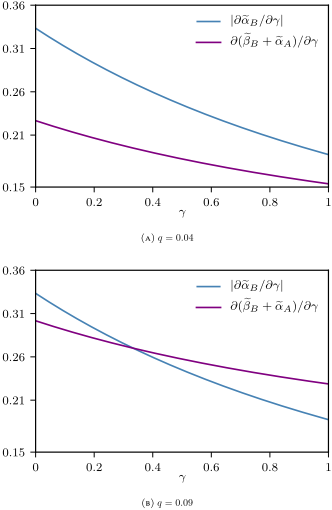

In [73]:
from IPython.display import Image, display

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed_papers"
    / "images"
    / "doc_127ff1e6f5f2"
    / "figure_0002.png"
)

display(Image(filename=str(figure_path)))

In [74]:
evaluation_set[22]["query"] = (
    "For the plot showing trading aggressiveness as a function of firm B's "
    "quantitative investing level, how do the two plotted measures change "
    "as γ increases, and how does their relationship differ between "
    "q = 0.04 and q = 0.09?"
)

evaluation_set[22]["relevant_chunks"] = [
    {
        "chunk_id": "chunk_f64d07c7962ba53f",
        "relevance": 3
    }
]

print(evaluation_set[22])

{'query_id': 'FIG01', 'category': 'figure_based', 'query': "For the plot showing trading aggressiveness as a function of firm B's quantitative investing level, how do the two plotted measures change as γ increases, and how does their relationship differ between q = 0.04 and q = 0.09?", 'relevant_chunks': [{'chunk_id': 'chunk_f64d07c7962ba53f', 'relevance': 3}]}


In [75]:
other_figures = [
    chunk for chunk in figure_chunks
    if chunk["source_file"] != "ssrn-5231379.pdf"
]

print("Other-paper figure chunks:", len(other_figures))

for i, chunk in enumerate(other_figures):
    evidence = chunk.get("evidence", [{}])[0]

    print(f"\n[{i:02d}] {chunk['chunk_id']}")
    print("Source:", chunk["source_file"])
    print("Pages:", chunk["pages"])
    print("Section:", chunk["section_path"])
    print("Caption:", evidence.get("caption", ""))
    print("Image:", evidence.get("image_path", ""))
    print("-" * 80)

Other-paper figure chunks: 67

[00] chunk_e3c9f6002dcbe732
Source: 2605.28853v1.pdf
Pages: [3]
Section: ['C. Loss Function Construction']
Caption: Fig. 1: Typical Forward Pass
Image: images\doc_1a26eba6c592\figure_0001.png
--------------------------------------------------------------------------------

[01] chunk_8afcd87c39cbac32
Source: 2605.28853v1.pdf
Pages: [5]
Section: ['E. Hyperparameter Optimization']
Caption: Fig. 2: Walk-Forward Procedure
Image: images\doc_1a26eba6c592\figure_0002.png
--------------------------------------------------------------------------------

[02] chunk_e1057e70043454f2
Source: 2605.28853v1.pdf
Pages: [7]
Section: ['V. RESULTS']
Caption: 
Image: images\doc_1a26eba6c592\figure_0003.png
--------------------------------------------------------------------------------

[03] chunk_31c4d5cd07d75738
Source: 2605.28853v1.pdf
Pages: [7]
Section: ['V. RESULTS']
Caption: Fig. 3: Sharpe and CVaR Distribution
Image: images\doc_1a26eba6c592\figure_0004.png
----------

Chunk ID: chunk_7595f8611d341b74
Source: 2605.27848v1.pdf
Pages: [3]
Caption: Figure 7. 3-State HMM Regime Classification (Viterbi Path)
Image: images\doc_6a8ad8a50fb1\figure_0007.png


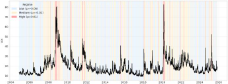

In [76]:
figure_02 = next(
    chunk for chunk in figure_chunks
    if chunk["chunk_id"] == "chunk_7595f8611d341b74"
)

print("Chunk ID:", figure_02["chunk_id"])
print("Source:", figure_02["source_file"])
print("Pages:", figure_02["pages"])
print("Caption:", figure_02["evidence"][0]["caption"])
print("Image:", figure_02["evidence"][0]["image_path"])

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed_papers"
    / figure_02["evidence"][0]["image_path"]
)

from IPython.display import Image, display
display(Image(filename=str(figure_path)))

In [77]:
for chunk in other_figures:
    evidence = chunk.get("evidence", [{}])[0]
    caption = evidence.get("caption", "")

    if caption:
        print(f"{chunk['chunk_id']} | {chunk['source_file']} | "
              f"Pages: {chunk['pages']}")
        print("Caption:", caption)
        print("Image:", evidence.get("image_path"))
        print("-" * 100)

chunk_e3c9f6002dcbe732 | 2605.28853v1.pdf | Pages: [3]
Caption: Fig. 1: Typical Forward Pass
Image: images\doc_1a26eba6c592\figure_0001.png
----------------------------------------------------------------------------------------------------
chunk_8afcd87c39cbac32 | 2605.28853v1.pdf | Pages: [5]
Caption: Fig. 2: Walk-Forward Procedure
Image: images\doc_1a26eba6c592\figure_0002.png
----------------------------------------------------------------------------------------------------
chunk_31c4d5cd07d75738 | 2605.28853v1.pdf | Pages: [7]
Caption: Fig. 3: Sharpe and CVaR Distribution
Image: images\doc_1a26eba6c592\figure_0004.png
----------------------------------------------------------------------------------------------------
chunk_582259f484499ed5 | 2605.21504v1.pdf | Pages: [7]
Caption: Figure 1: Parameter heatmap comparing MV and UV forecasting accuracy across window lengths and horizons (based on MAPE). The upper plot is for Rates and the lower one is for Stocks. In each plot, the lef

Chunk ID: chunk_b2b2391b0146a193
Source: 2605.27848v1.pdf
Pages: [1]
Caption: Figure 1. Daily Log Returns of SPY, TLT, and GLD
Image: images\doc_6a8ad8a50fb1\figure_0002.png


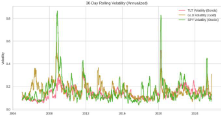

In [78]:
figure_02 = next(
    chunk for chunk in figure_chunks
    if chunk["chunk_id"] == "chunk_b2b2391b0146a193"
)

print("Chunk ID:", figure_02["chunk_id"])
print("Source:", figure_02["source_file"])
print("Pages:", figure_02["pages"])
print("Caption:", figure_02["evidence"][0]["caption"])
print("Image:", figure_02["evidence"][0]["image_path"])

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed_papers"
    / figure_02["evidence"][0]["image_path"]
)

from IPython.display import Image, display
display(Image(filename=str(figure_path)))

In [79]:
for chunk in other_figures:
    evidence = chunk.get("evidence", [{}])[0]
    caption = evidence.get("caption", "")

    if caption and chunk["chunk_id"] != "chunk_b2b2391b0146a193":
        print(f"{chunk['chunk_id']} | {chunk['source_file']} | Pages: {chunk['pages']}")
        print("Caption:", caption)
        print("Image:", evidence.get("image_path"))
        print("-" * 100)

chunk_e3c9f6002dcbe732 | 2605.28853v1.pdf | Pages: [3]
Caption: Fig. 1: Typical Forward Pass
Image: images\doc_1a26eba6c592\figure_0001.png
----------------------------------------------------------------------------------------------------
chunk_8afcd87c39cbac32 | 2605.28853v1.pdf | Pages: [5]
Caption: Fig. 2: Walk-Forward Procedure
Image: images\doc_1a26eba6c592\figure_0002.png
----------------------------------------------------------------------------------------------------
chunk_31c4d5cd07d75738 | 2605.28853v1.pdf | Pages: [7]
Caption: Fig. 3: Sharpe and CVaR Distribution
Image: images\doc_1a26eba6c592\figure_0004.png
----------------------------------------------------------------------------------------------------
chunk_582259f484499ed5 | 2605.21504v1.pdf | Pages: [7]
Caption: Figure 1: Parameter heatmap comparing MV and UV forecasting accuracy across window lengths and horizons (based on MAPE). The upper plot is for Rates and the lower one is for Stocks. In each plot, the lef

Chunk ID: chunk_68993e8fc7c968bc
Source: 2605.27945v1.pdf
Pages: [4]
Caption: Figure 5 Market vs Model (Lewis vs FFT)


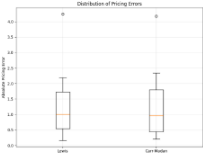

In [80]:
figure_03 = next(
    chunk for chunk in figure_chunks
    if chunk["chunk_id"] == "chunk_68993e8fc7c968bc"
)

figure_path = (
    PROJECT_ROOT
    / "data"
    / "processed_papers"
    / figure_03["evidence"][0]["image_path"]
)

print("Chunk ID:", figure_03["chunk_id"])
print("Source:", figure_03["source_file"])
print("Pages:", figure_03["pages"])
print("Caption:", figure_03["evidence"][0]["caption"])

from IPython.display import Image, display
display(Image(filename=str(figure_path)))

In [81]:
# Find nearby information around the selected figure
target_chunk_id = "chunk_68993e8fc7c968bc"

# Locate the target chunk
target_idx = next(
    i for i, c in enumerate(all_chunks)
    if c["chunk_id"] == target_chunk_id
)

print("Target index:", target_idx)
print("Total chunks:", len(all_chunks))

# Show nearby chunks
for i in range(max(0, target_idx - 5), min(len(all_chunks), target_idx + 6)):
    chunk = all_chunks[i]

    print("\n" + "=" * 100)
    print("INDEX:", i)
    print("CHUNK:", chunk["chunk_id"])
    print("SOURCE:", chunk["source_file"])
    print("PAGES:", chunk["pages"])
    print("SECTION:", chunk["section_path"])
    print("TYPE:", chunk["chunk_type"])

    text = chunk.get("text", "")
    print("TEXT:", text[:1500])

    evidence = chunk.get("evidence", [])
    for e in evidence:
        if e.get("caption"):
            print("CAPTION:", e["caption"])

Target index: 510
Total chunks: 1141

INDEX: 505
CHUNK: chunk_3c3dd89c78646243
SOURCE: 2605.27945v1.pdf
PAGES: [3]
SECTION: ['4.1.2 Calibration via Carr-Madan (1999) FFT Approach']
TYPE: table_evidence
TEXT: Table 3 Pricing metrics Table 3 Pricing metrics | Metric | Lewis | Carr-Madan | |----------|---------|--------------| | MSE | 2.226 | 2.262 | | MAE | 1.23 | 1.22 |
CAPTION: Table 3 Pricing metrics

INDEX: 506
CHUNK: chunk_e3c8cbd3869ed518
SOURCE: 2605.27945v1.pdf
PAGES: [4]
SECTION: ['4.1.2 Calibration via Carr-Madan (1999) FFT Approach']
TYPE: table_evidence
TEXT: Table 4 Comparison: Lewis vs Carr-Madan Table 4 Comparison: Lewis vs Carr-Madan | Parameter | Lewis | Carr- Madan | % Difference | |-------------|---------|---------------|-----------------------------------| | κ | 0.3981 | 0.4029 | 1.22% | | θ | 0.08748 | 0.08748 | 0.00% | | σ | ~0 | ~0 | Large % because tiny denominators | | ρ | 0.9906 | 0.9906 | 0.00% | | v₀ | 0.10157 | 0.10156 | 0.01% |
CAPTION: Table 4 Comparison: L

In [82]:
for i in range(495, 511):
    chunk = all_chunks[i]

    print("\n" + "=" * 100)
    print("INDEX:", i)
    print("CHUNK:", chunk["chunk_id"])
    print("TYPE:", chunk["chunk_type"])
    print("PAGES:", chunk["pages"])
    print("TEXT:", chunk.get("text", "")[:2000])


INDEX: 495
CHUNK: chunk_f07b90bac9d22d04
TYPE: formula_evidence
PAGES: [2]
TEXT: form: 𝑃(0, 𝑇) = 𝐴(0, 𝑇) 𝑒 -𝐵(0,𝑇)𝑟0 with: 𝐵(0, 𝑇) = 2(𝑒κ𝑇-1)

INDEX: 496
CHUNK: chunk_6c2829d74911da13
TYPE: formula_evidence
PAGES: [2]
TEXT: (κ+γ)(𝑒κ𝑇-1)+2γ

INDEX: 497
CHUNK: chunk_c5e81e5c62227090
TYPE: formula_evidence
PAGES: [2]
TEXT: 𝐴(0, 𝑇) = [ 2γ 𝑒 (κ+γ)𝑇/2 (κ + γ)(𝑒 κ𝑇 - 1) + 2γ]2κθ σ2

INDEX: 498
CHUNK: chunk_5083b24812517420
TYPE: formula_evidence
PAGES: [2]
TEXT: 𝑀𝑆𝐸(𝛩) = 1𝑁 ∑ (𝑃𝑚𝑜𝑑𝑒𝑙(0, 𝑇𝑖;𝛩) -𝑃𝑚𝑎𝑟𝑘𝑒𝑡(0, 𝑇𝑖))2 𝑁𝑖=1

INDEX: 499
CHUNK: chunk_60fdff4f95f2a382
TYPE: formula_evidence
PAGES: [3]
TEXT: 𝑀𝑆𝐸 = 1𝑁 ∑(𝐶𝑖𝑚𝑜𝑑𝑒𝑙 - 𝐶𝑖𝑚𝑎𝑟𝑘𝑒𝑡 )2 𝑁 𝑖=1

INDEX: 500
CHUNK: chunk_ceccfff2d1478248
TYPE: formula_evidence
PAGES: [3]
TEXT: 𝐶 = 𝑆0𝑃1 -𝐾𝑒𝑥𝑝(-𝑟𝑇)𝑃2

INDEX: 501
CHUNK: chunk_55ac876b6456a65a
TYPE: formula_evidence
PAGES: [3]
TEXT: 𝑀𝑆𝐸 = 1𝑁 ∑(𝐶𝑖𝑚𝑜𝑑𝑒𝑙 - 𝐶𝑖𝑚𝑎𝑟𝑘𝑒𝑡 )2 𝑁 𝑖=1

INDEX: 502
CHUNK: chunk_e6782ff1bc59a54d
TYPE: table_evidence
PAGES: [3]
TEXT: Table 2. Calibrated Parameters Table 2. Calibrated Paramete

In [84]:
evaluation_set[23] = {
    "query_id": "FIG02",
    "category": "figure_based",
    "query": (
        "In the market-versus-model pricing comparison between the Lewis "
        "and Carr-Madan methods, what does the distribution of pricing "
        "errors indicate about the typical error, spread, and outliers, "
        "and how do these observations compare with the reported MSE and "
        "MAE values?"
    ),
    "relevant_chunks": [
        {
            "chunk_id": "chunk_68993e8fc7c968bc",
            "relevance": 3
        },
        {
            "chunk_id": "chunk_3c3dd89c78646243",
            "relevance": 3
        }
    ]
}

print(evaluation_set[23])

{'query_id': 'FIG02', 'category': 'figure_based', 'query': 'In the market-versus-model pricing comparison between the Lewis and Carr-Madan methods, what does the distribution of pricing errors indicate about the typical error, spread, and outliers, and how do these observations compare with the reported MSE and MAE values?', 'relevant_chunks': [{'chunk_id': 'chunk_68993e8fc7c968bc', 'relevance': 3}, {'chunk_id': 'chunk_3c3dd89c78646243', 'relevance': 3}]}


In [85]:
# Find chunks from the same document that are close together
# and contain complementary information.

for i in range(len(all_chunks) - 2):
    c1 = all_chunks[i]
    c2 = all_chunks[i + 1]

    if (
        c1["source_file"] == c2["source_file"]
        and c1["chunk_type"] not in ["figure_evidence"]
        and c2["chunk_type"] not in ["figure_evidence"]
        and c1["section_path"] == c2["section_path"]
    ):
        print("\n" + "=" * 100)
        print("INDEX:", i, "→", i + 1)
        print("SOURCE:", c1["source_file"])
        print("SECTION:", c1["section_path"])
        print("\nCHUNK 1:", c1["chunk_id"])
        print(c1.get("text", "")[:1000])
        print("\nCHUNK 2:", c2["chunk_id"])
        print(c2.get("text", "")[:1000])


INDEX: 1 → 2
SOURCE: ssrn-5231379.pdf
SECTION: ['1. Introduction']

CHUNK 1: chunk_e9dbc9860c200c4a
Advances in artificial intelligence (AI), along with the availability of big data and computing power, have changed how investment decisions are made. These developments have enabled a new generation of investors, commonly known as quants, who use quantitative models and algorithms to identify trading opportunities, construct portfolios, and execute trades at scale. While quantitative investing was once limited to a niche subset of hedge funds, it has become increasingly mainstream over the past two decades. Today, it is widely accessible, even to retail investors, through quantitative trading platforms and mutual funds (e.g., Beggs and Hill-Kleespie 2025). As quants take up a larger share of trading activity, concerns have emerged about how their collective behavior might affect market stability. 1 Episodes of extreme price dislocations such as the August 2007 Quant Meltdown and the Ma

In [86]:
selected_ids = [
    "chunk_09712835319a6dd6",
    "chunk_d9600aaaec5dcae2"
]

for chunk_id in selected_ids:
    chunk = next(
        c for c in all_chunks
        if c["chunk_id"] == chunk_id
    )

    print("\n" + "=" * 100)
    print("CHUNK ID:", chunk["chunk_id"])
    print("SOURCE:", chunk["source_file"])
    print("PAGES:", chunk["pages"])
    print("SECTION:", chunk["section_path"])
    print("TYPE:", chunk["chunk_type"])
    print("\nTEXT:")
    print(chunk.get("text", ""))


CHUNK ID: chunk_09712835319a6dd6
SOURCE: ssrn-5231379.pdf
PAGES: [3, 4]
SECTION: ['1. Introduction']
TYPE: semantic

TEXT:
The quant department has superior information processing capacity: it observes both the public signal v1 and a noisy signal θ2 about a second component of the asset's value, v = v1 + v2. In contrast, the discretionary department observes only v1. Despite the informational advantage, the quant is strategically weaker. It optimises trades based on signals but incorrectly perceives that firmA does not adjust its strategy in response, i.e., it is strategically myopic. In the baseline model, we assume complete strategic myopia, but later relax this assumption to allow for partial responsiveness. We show that the strategic interactions between quants and discretionary investors give rise to three key effects. First, as the quantitative investing level increases, firmB becomes more effective at extracting information from the additional signal θ2 and increases its tradin

In [87]:
evaluation_set[24] = {
    "query_id": "MULTI01",
    "category": "multi_chunk_reasoning",
    "query": (
        "How do the processing capacity, strategic myopia, and internalising "
        "effects interact as quantitative investing increases, and why does "
        "this produce different patterns of overall trading aggressiveness "
        "for low, intermediate, and high values of q?"
    ),
    "relevant_chunks": [
        {
            "chunk_id": "chunk_09712835319a6dd6",
            "relevance": 3
        },
        {
            "chunk_id": "chunk_d9600aaaec5dcae2",
            "relevance": 3
        }
    ]
}

print(evaluation_set[24])

{'query_id': 'MULTI01', 'category': 'multi_chunk_reasoning', 'query': 'How do the processing capacity, strategic myopia, and internalising effects interact as quantitative investing increases, and why does this produce different patterns of overall trading aggressiveness for low, intermediate, and high values of q?', 'relevant_chunks': [{'chunk_id': 'chunk_09712835319a6dd6', 'relevance': 3}, {'chunk_id': 'chunk_d9600aaaec5dcae2', 'relevance': 3}]}


In [89]:
# Find chunks mentioning Sharpe ratio from each PDF
from collections import defaultdict

sharpe_by_doc = defaultdict(list)

for chunk in all_chunks:
    text = chunk.get("text", "").lower()

    if "sharpe ratio" in text:
        sharpe_by_doc[chunk["source_file"]].append(chunk)

for source, chunks in sharpe_by_doc.items():
    print("\n" + "=" * 100)
    print("DOCUMENT:", source)
    print("MATCHING CHUNKS:", len(chunks))

    for chunk in chunks[:5]:
        print(
            f"\n{chunk['chunk_id']} | "
            f"Pages: {chunk['pages']} | "
            f"Section: {chunk['section_path']}"
        )
        print(chunk.get("text", "")[:700])


DOCUMENT: 2605.28853v1.pdf
MATCHING CHUNKS: 8

chunk_c409e7bb9b421a3c | Pages: [1] | Section: ['Financially Guided Deep Portfolio Optimization']
Rahul Fernandes Department of Software Engineering Rochester Institute of Technology Rochester, New York, USA rf4074@rit.edu Abstract-Portfolio optimization in real-world financial markets is notoriously difficult due to non-stationarity, noisy data, and high transaction costs. Standard predict-then-optimize methods first forecast returns and then solve for weights, compounding prediction errors and often failing under regime shifts. We propose an end-to-end framework that directly optimizes differentiable surrogates of key financial metrics - Sharpe ratio, Omega ratio, Conditional Value-at-Risk (CVaR), and Risk Parity - allowing neural networks to learn portfolio weights via backpropagation

chunk_7bc4aeb6d1f00a7d | Pages: [1] | Section: ['I. INTRODUCTION']
We evaluate seven neural architectures with two custom loss functions on a CRSP datas

In [90]:
selected_ids = [
    "chunk_3adaa213317c460b",  # 2605.28853v1.pdf
    "chunk_e1d74bb73b0157c9"   # 2605.27848v1.pdf
]

for chunk_id in selected_ids:
    chunk = next(
        c for c in all_chunks
        if c["chunk_id"] == chunk_id
    )

    print("\n" + "=" * 100)
    print("CHUNK ID:", chunk["chunk_id"])
    print("SOURCE:", chunk["source_file"])
    print("PAGES:", chunk["pages"])
    print("SECTION:", chunk["section_path"])
    print("TYPE:", chunk["chunk_type"])
    print("\nTEXT:")
    print(chunk.get("text", ""))


CHUNK ID: chunk_3adaa213317c460b
SOURCE: 2605.28853v1.pdf
PAGES: [5]
SECTION: ['F. Candidate Model Selection']
TYPE: semantic

TEXT:
Since, the risk-adjusted metrics (Sharpe, Sortino, Calmar, Omega) were highly correlated, and tail metrics (CVaR, MDD) were highly correlated, we selected Sharpe ratio as the primary measure of risk-adjusted return and CVaR as the primary measure of tail risk. We then applied Pareto dominance on the validation-set performance using these two metrics. This yielded a frontier of non-dominated model-loss combinations. As a secondary check, we performed PCA on all seven metrics. PC1 captured risk-adjusted metrics and PC2 captured tail risk metrics; we used PC1 and inverted PC2 to obtain a 'higher-is-better' space. The Pareto frontier in this space added one more model. The union of both frontiers gave six candidates out of fourteen model-loss combinations: AttentionLSTM-CustomLossB, DeformTime-CustomLossB, TemporalTransformer-CustomLossB, PatchTST-CustomLoss

In [91]:
evaluation_set.append({
    "query_id": "MULTIDOC01",
    "category": "cross_document",
    "query": (
        "How is risk-adjusted performance treated differently in the two studies: "
        "how does the first study use the Sharpe ratio during model selection, "
        "and how does the second study use Sharpe ratio to characterize the "
        "performance of its RL-based portfolio allocation strategy?"
    ),
    "relevant_chunks": [
        {
            "chunk_id": "chunk_3adaa213317c460b",
            "relevance": 3
        },
        {
            "chunk_id": "chunk_e1d74bb73b0157c9",
            "relevance": 3
        }
    ]
})

print(evaluation_set[-1])

{'query_id': 'MULTIDOC01', 'category': 'cross_document', 'query': 'How is risk-adjusted performance treated differently in the two studies: how does the first study use the Sharpe ratio during model selection, and how does the second study use Sharpe ratio to characterize the performance of its RL-based portfolio allocation strategy?', 'relevant_chunks': [{'chunk_id': 'chunk_3adaa213317c460b', 'relevance': 3}, {'chunk_id': 'chunk_e1d74bb73b0157c9', 'relevance': 3}]}


In [92]:
import json
from pathlib import Path

OUTPUT_PATH = PROJECT_ROOT / "data" / "outputs" / "evaluation_set.json"

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(evaluation_set, f, indent=2, ensure_ascii=False)

print("Saved:", OUTPUT_PATH)
print("Total evaluations:", len(evaluation_set))

Saved: c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\outputs\evaluation_set.json
Total evaluations: 41


In [93]:
evaluation_set = [
    item for item in evaluation_set
    if item.get("query", "").strip()
    and item.get("relevant_chunks")
]

print("Completed evaluations:", len(evaluation_set))

Completed evaluations: 26


In [94]:
from collections import Counter

category_counts = Counter(
    item["category"] for item in evaluation_set
)

print("Total:", len(evaluation_set))
print("\nCategory distribution:")

for category, count in category_counts.items():
    print(f"{category}: {count}")

Total: 26

Category distribution:
semantic_factual: 10
formula_quantitative: 6
table_based: 6
figure_based: 2
multi_chunk_reasoning: 1
cross_document: 1


In [95]:
import json
from pathlib import Path

OUTPUT_PATH = PROJECT_ROOT / "data" / "outputs" / "evaluation_set.json"

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(evaluation_set, f, indent=2, ensure_ascii=False)

print("Saved:", OUTPUT_PATH)
print("Final evaluation count:", len(evaluation_set))

Saved: c:\Users\MD RAJA\Quant_Research_Intelligence_System\data\outputs\evaluation_set.json
Final evaluation count: 26
